# Bayesian model selection


Fitting models to S(Q,$\omega$) is sort of a nightmare, lots of rotational and translational motions show up as Lorentzian meaning we can often be fitting lots of very similar line shapes which can result in very degenerate fits and it sort of becomes pick whichever values you like, which is not great. It can be very difficult to accurately assign intensities etc. to different motions. 

This is often less of a problem if we fit very simple models, but ideally we want to be able to extract complex nuanced dynamics from QENS!

In my opinion a few things can help us to do this: 

1) Fitting rigorous physical models - We want to encode us much physics in the model as we can to ensure we are accurately representing the particle motion
2) Fit amplitudes and widths simultaneously across Q - If we constrain our models in terms of amplitudes and shape we can better assign motions

and perhaps most importantly 

3) Ensure we can justify model complexity - to misquote Kevin from the Office:


    **" Why use many parameters when few do trick? "**

    or in the immortal words of Von Neumann:

    **" Don't fit an elephant "**


Nested sampling is a tool we can use to help with this, I will discuss in more detail a bit further down!





## Accurately encoding physics

Lots of people much smarter than me have done much better jobs explaining this kind of thing, I think the below books and papers are all very useful: 

[Neutron Scattering Fundamental - Felix Fernandez-Alonso](https://search.library.berkeley.edu/discovery/fulldisplay?vid=01UCS_BER:UCB&docid=alma991008925609706532&context=L) - Chapter 1 goes through alot of these derivations in detail

[QENS and MD simulation as complementary techniques for studying diffusion in zeolites - Jobic](https://www.sciencedirect.com/science/article/pii/S1387181106005725?via%3Dihub) - Practical fitting advice and models

[Quasielastic neutron scattering - Bee](https://inis.iaea.org/records/c1rd1-75d64) - If you are good at maths and brave!



There are obviously lots of others, but I found those 3 very useful!


To sum up, any expontentially decaying time correlation becomes a Lorentzian in (Q, $\omega$) space such that: 

\begin{equation}
    S_{inc}^{mode}(Q,\omega) = \frac{A}{\pi} \cdot \frac{\Gamma}{\Gamma^2 + (\omega - \omega_0)^2}.
\end{equation}



often we will consider slower translational motions and faster rotational motions as separate dynamic phenomenon (which is an approximation) these can then be combined via a convolution: 


\begin{equation}
    S_{inc}(Q,\omega) = S_{inc}^{T}(Q,\omega) \otimes S_{inc}^{R}(Q,\omega).
\end{equation}

There is a simple analytical solution to the convolution of two lorentzians which means we don't actually need to do it! 


We then need to decide how we are going to describe our rotational and translational motion as a function of Q and $\omega$. 

## For Translational motion: 


\begin{equation}
    S^T(Q, \omega) = e^{-\mathbf{Q}^2 \langle u^2 \rangle / 3} \left[\frac{1}{\pi} \frac{\Gamma_T(Q)}{\omega^2 + \Gamma_T(Q)^2} \right].
\end{equation}

where for Fickian motion: 
\begin{equation}
    \Gamma_T = D * Q^2
\end{equation}

**Also have a look at the models we can use for jump diffusion!**


## For rotational motion: 

For a simple isotropic rotation i.e. random rotation within a sphere $R_g$: 

For the rotational model we will be using the HWHM of the Lorentzian $\Gamma_R$ remains constant as a function of Q.

\begin{equation}
S^R(Q, \omega) =  j_0^2(QR_{g}) + \sum_{l>0} 
(2l + 1) \, j_l^2(QR_{g}) 
\left[ \frac{1}{\pi} \frac{l(l+1)\Gamma_{R}}{\omega^2 + l(l+1)\Gamma_{R}^2} \right] .
\end{equation}

(A full derivation of this can be found in the benzene paper linked in section 1)


We then often add a flat background term to account for any terms that are too fast for energy window and also convolve with our resolution function.



**BUT**


We know from earlier that the rotation of benzene in NOT isotropic! We can also derive a model for the anisotropic rotation of benzene, considering benzene as an axially symmetric disk rotor. There is also a derivation of this in the paper 

In time space: 

\begin{equation}
    I(Q, t, \theta) = \sum_{l=0}^{\infty}(2l+1) \left[j_l(QR)\right]^2 C_l(t, \theta).
\end{equation}


which we can then convert to frequency space:

\begin{equation}
    S(Q, \omega, \theta) = \frac{1}{2\pi}\int_{-\infty}^{\infty} I(Q, t, \theta)\, e^{-i\omega t}\, \mathrm{d}t
    = \sum_{l=0}^{\infty}(2l+1)\left[j_l(QR)\right]^2 \tilde{C}_l(\omega, \theta),

\end{equation}

where, for an axially symmetric rotator,

\begin{equation}
    \tilde{C}_l(\omega, \theta) = \sum_{m=-l}^{l}\left[d^{\,l}_{m0}(\theta)\right]^2 \mathcal{L}\left(\omega; \Gamma_{lm}\right),
    \qquad
    \Gamma_{lm} = l(l+1)D_t + m^2\left(D_s - D_t\right),
\end{equation}

**Note: This was all done by someone much better at maths than me. The practical take away is that when we do the expansion we end up with two rotational diffusion coefficients $D_s$ and $D_T$. This model has an extra fitting parameter!**

Expanded up to $l=2$ it looks like: 


\begin{equation}
    \begin{aligned}
    S^R(Q, \omega) = \frac{1}{2\pi} \Bigg( & j_0^2(QR) \delta(\omega) + 3j_1^2(QR)\left[\frac{1}{\pi}\frac{D_s+D_t}{\omega^2+(D_s+D_t)^2}\right] \\
     & + 5j_2^2(QR) \left[\frac{1}{4}\frac{1}{\pi}\frac{6D_t}{\omega^2 + (6D_t)^2} + \frac{3}{4} \frac{1}{\pi} \frac{4D_s + 2D_t}{\omega^2 + (4D_s + 2D_t)^2} \right]\Bigg).
    \end{aligned}
\end{equation}


# Nested sampling and Bayesian model selection
For Bayesian statistics:

$$
\underbrace{\mathcal{L}(\theta)}_{\text{Likelihood}} \times \underbrace{\pi(\theta)\,\mathrm{d}\theta}_{\text{Prior}} = \underbrace{Z}_{\text{Evidence}} \times \underbrace{p(\theta)\,\mathrm{d}\theta}_{\text{Posterior}}
$$

Traditionally, in say MCMC sampling, we discard the evidence via a proportionality, $p(\theta) \propto \mathcal{L}(\theta)\,\pi(\theta)$, since $Z$ is a constant normalisation for a given model and does not affect the shape of the posterior. This is sufficient for parameter estimation, but the value of $Z$ is then lost, so models cannot be directly compared. Integrating both sides over $\theta$, and noting that the posterior is normalised, gives

$$
Z = \int \mathcal{L}(\theta)\,\pi(\theta)\,\mathrm{d}\theta.
$$

Nested sampling targets $Z$ as its primary quantity. The posterior is then obtained as a by-product, by weighting each dead point by $p_i = \mathcal{L}_i\,\Delta X_i / Z$, so a single run gives both parameter estimates and the evidence for model selection.

**This evidence term inherently penalises overparameterisation, as each additional parameter spreads the prior mass over a larger volume, much of which has low likelihood.**

 A model is therefore rewarded only if its extra parameters improve the fit enough to offset this dilution, an automatic Occam's razor. 
 
 The prolem is $Z$ is an $n$ dimensional integral over all our different parameter priors, which would be a nightmare to caclulate. The cleverness of nested sampling is that the evidence is computed by transforming the multidimensional integral into a one-dimensional integral over the enclosed prior volume, $Z = \int_0^1 \mathcal{L}(X)\,\mathrm{d}X$. 


 For more information on how nested sampling works, these papers are both very well written and very accessible: 

[Nested sampling for general Bayesian computation - Skilling](https://projecteuclid.org/journals/bayesian-analysis/volume-1/issue-4/Nested-sampling-for-general-Bayesian-computation/10.1214/06-BA127.full)

[Nested sampling for physical scientists](https://arxiv.org/abs/2205.15570)


[or see this interactive course book](https://bri-sc.github.io/special-topics-ai-ml/prob-modelling/nested-sampling.html)



Once we have calculated the evidence for the two models we want to compare, we can calculate the Bayes factor,

$$
B_{12} = \frac{Z_1}{Z_2}, \qquad \ln B_{12} = \ln Z_1 - \ln Z_2.
$$

If we assign equal prior probability to each model, $B_{12}$ is equal to the posterior odds of model 1 over model 2. We interpret $\ln B_{12}$ on the following scale:

| $\lvert\ln B_{12}\rvert$ | Strength of evidence |
|---|---|
| < 1 | Inconclusive |
| 1 – 2.5 | Weak |
| 2.5 – 5 | Moderate |
| > 5 | Strong |

A positive value favours model 1 and a negative value favours model 2. If we have 'strong evidence' for the more complex model then its use is justified!




# Applying nested sampling to our Benzene simulation!



First we will load in the benzene data, define our anisotropic and isotropic models and then we can run the nested sampling and calculate the log evidence.

In [11]:
import h5py
from pathlib import Path
import scipp as sc
import matplotlib.pyplot as plt
import numpy as np
from _fig_params import colors
import sys

DATA = Path("../../Data/benzene")
MDA = DATA / "incoh.mda"
COMP = "total"
HBAR = 0.6582119569  # meV per rad/ps

inc_dict = {}
with h5py.File(MDA, "r") as f:
    inc_dict["q"] = f["disf/axes/q"][...] / 10
    inc_dict["omega"] = f["disf/axes/omega"][...] * HBAR
    inc_dict["S"] = f[f"disf/s(q,f)/{COMP}"][...] / HBAR


def create_scipp_array(S, q, omega):
    half_bin_omega = (np.diff(omega) / 2)[0]
    omega = np.append(omega - half_bin_omega, omega[-1] + half_bin_omega)

    half_bin_q = (np.diff(q) / 2)[0]
    q = np.append(q - half_bin_q, q[-1] + half_bin_q)

    sqw = sc.DataArray(
        data=sc.array(dims=["q", "omega"], values=S),
        coords={
            "q": sc.array(dims=["q"], values=q, unit="1/Angstrom"),
            "omega": sc.array(dims=["omega"], values=omega, unit="meV"),
        },
    )
    return sqw


sqw = create_scipp_array(inc_dict["S"], inc_dict["q"], inc_dict["omega"])
q_bins_let = sc.linspace("q", 0.6, 1.8, num=13, unit="1/Angstrom") # We are only using 12 Q bins to reduce the calculation time! 
omega_bins_let = sc.linspace("omega", -2.25, 2.25, num=300, unit="meV")
bin_dict_let= {"q": q_bins_let, "omega": omega_bins_let}
inc = sqw.rebin(**bin_dict_let)
# inc = inc /  inc.min() # Set the minimum value to 1


q_mids = sc.midpoints(q_bins_let)
omega_mids = sc.midpoints(omega_bins_let)

First we can split our model up into separate functions to make it all a bit simpler. 

We want several functions: 

* A lorentzian function 
* A fickian diffusion HWHM function ($DQ^2$)
* A rotational diffusion HWHM function  (A flat HWHM)
* A function that combines our rotational and translational motions and adds a backgound 


(for the background i would assume a linear Q dependence of form bkg = mQ + c - This is very much an assumption but fitting 13 independent backgrounds will slow everything down massively!)

We want to be able to input omega values and q values into our model and output an array that contains our model predictions. 

(Set the radius of gyration of the benzene to 2.48A - How can we justify choosing this radius?)

Our model is going to need several parameters: 

* Fickian diffusion coefficient 
* Rotational diffusion coefficient 
* some sort of q-indepdent normalising factor (may not need if you set things up nicely)
* Debye waller decay factor ($u^2)
* flat background term at each Q

We are looking for a functional call of the kind: 

```def isotropic_model(omega, q, D_fick, D_rot, normaliser, u2, bkg_m, bkg_c, radius=2.48, l_max=3):```


Test your model with code like: 

```isotropic_model(omega_mids.values, q_mids.values, D_fick = 0.13, D_rot = 0.1,normaliser = 3, u2 = 0.3, bkg_m = 0.4, bkg_c = 3,  radius = 2.48, l_max = 3)```

In [12]:
from scipy.special import spherical_jn

def fickian(q: np.ndarray, grad: float) -> np.ndarray:
    """
    Fickian diffusion HWHM function for QENS.
    """
    return grad * q**2

def lorentzian(x: np.ndarray, gamma: np.ndarray, A: np.ndarray) -> np.ndarray:
    """
    Lorentzian function
    """
    x0 = 0
    return (A / np.pi) * (gamma / ((x - x0) ** 2 + gamma**2))

def rotational_diffusion(q: np.ndarray, D_rot: float, l: int) -> np.ndarray:
    """
    HWHM of the rank-l mode for isotropic rotational diffusion: l(l+1) D_rot.
    """
    return np.ones_like(q) * l * (l + 1) * D_rot


def isotropic_model(omega, q, D_fick, D_rot, normaliser, u2, bkg_m, bkg_c, radius=2.48, l_max=5):
    """
    Fickian translation convolved with isotropic rotational diffusion
    Returns S with shape (len(q), len(omega)).
    """

    q = q.reshape(-1,1) # This helps to get the array shapes working


    # Calculate our fickian HWHM and amplitude decay 
    gamma_fick = fickian(q, D_fick)
    debye_waller = np.exp(-(q**2) * u2 / 3)
    qr = q * radius

    bkg = bkg_m * q + bkg_c   # linear in q, centred

    # Calculate our rotational amplitudes and lorentzians
    s = np.zeros((q.shape[0], omega.shape[0]))
    for l in range(l_max + 1):
        amplitude = (2 * l + 1) * spherical_jn(l, qr) ** 2
        # Convolution of two Lorentzians is a Lorentzian with summed widths
        gamma = gamma_fick + rotational_diffusion(q, D_rot, l)
        s += lorentzian(omega, gamma, amplitude)

    
    return normaliser * debye_waller * s + bkg




test = isotropic_model(omega_mids.values, q_mids.values, D_fick = 0.13, D_rot = 0.1,normaliser = 3, u2 = 0.3, bkg_m = 0.4, bkg_c = 3,  radius = 2.48, l_max = 3)
print(f"model produces an output: {test} of shape {test.shape}")


model produces an output: [[3.29967728 3.30019429 3.30072137 ... 3.30072137 3.30019429 3.29967728]
 [3.35112647 3.35178389 3.3524539  ... 3.3524539  3.35178389 3.35112647]
 [3.40303585 3.40383356 3.40464624 ... 3.40464624 3.40383356 3.40303585]
 ...
 [3.72836602 3.72950945 3.73066969 ... 3.73066969 3.72950945 3.72836602]
 [3.76352866 3.76458581 3.76565778 ... 3.76565778 3.76458581 3.76352866]
 [3.79572644 3.7966722  3.79763057 ... 3.79763057 3.7966722  3.79572644]] of shape (12, 299)


Great we can now set up our nested sampling to calculate our bayesian evidence

In [13]:
# First we define the bounds of our priors, we do this in the order our model function call expects


bounds = (
    [(0.01,0.4),
    (0.01,0.8),
    (0.01,100),
    (0.01,1),
    (0,2),
    (0,6)]
    
)

# This function converts our prior into the format expected by Dynesty
def prior_transform(u):
    """
    Transform parameters to the prior space.

    :param u: parameters in the prior space

    :return: transformed parameters
    """

    return [i * (b[1] - b[0]) + b[0] for i, b in zip(u, bounds)]



# We define our log likelihood model
def log_likelihood(params, data, model, q_mid, omega):
    model_vals = model(omega, q_mid, *params)

    # This assumes a 5% variance on our data have a play with it, how does adding more uncertainty affect things?
    SQE = np.sum(((model_vals - data)**2 / (data * 0.05)))
    return -0.5 * SQE


def nll(params, data, model, q_mid, omega_mid) -> float:
    """
    Negative log likelihood model for optimisation
    """
    return -log_likelihood(params, data, model, q_mid, omega_mid)


from multiprocessing import Pool
import dynesty
import pickle

sampler = dynesty.NestedSampler(
        log_likelihood,
        prior_transform,
        len(bounds),
        logl_args=(inc.values, isotropic_model, q_mids.values, omega_mids.values))
sampler.run_nested(print_progress=True)
ns_res = sampler.results

with open("iso_model_fixed.pkl", "wb") as f:
    pickle.dump(ns_res.asdict(), f)

15593it [00:21, 725.82it/s, +500 | bound: 106 | nc: 1 | ncall: 71320 | eff(%): 22.724 | loglstar:   -inf < -46.268 <    inf | logz: -76.795 +/-  0.248 | dlogz:  0.001 >  0.509]   


Hopefully you have now run the sampler!


* Do the values look sensible? 
* What are their units?
* can we compare them to the values calculated in exercise 1?
* How does the model fit?
* How does changing the expansion of the spherical bessel functions affect the fit?

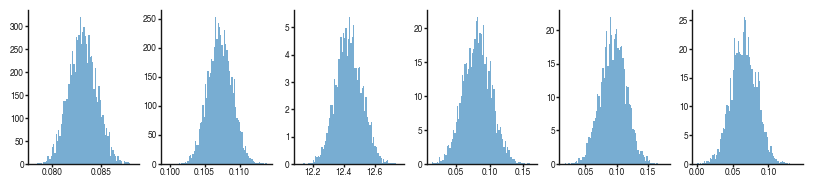

In [14]:
fig,ax = plt.subplots(1,6, figsize = (10,2))
for i in range(6):
    ax[i].hist(ns_res.samples_equal()[:,i], density = True, alpha = 0.6, bins = 80)



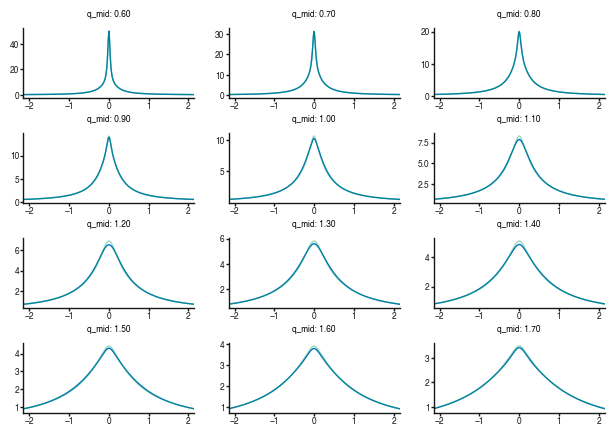

In [15]:
fig,ax = plt.subplots(4,3, figsize = (7.5,5))
ax = ax.ravel()
fig.subplots_adjust(hspace = 0.5)

for i in range(len(q_bins_let)-1):
    ax[i].plot(omega_mids.values, isotropic_model(omega_mids.values, q_mids.values, *ns_res.samples_equal()[-1])[i], color = colors[0])
    ax[i].errorbar(sc.midpoints(inc.coords['omega']).values,inc.values[i], color = colors[1], alpha = 0.4)
    ax[i].set_title(f"q_mid: {q_bins_let.values[i]:.2f}")
    ax[i].set_xlim(-2.15,2.15)


We can now run nested sampling on the more complex anisotropic model, is the extra complexity of this model justified by the data. Let's find out!

In [16]:
from math import comb

def planar_weight(l: int, m: int) -> float:
    """
    Weight [d^l_{m0}(pi/2)]^2, with +m and -m combined. Valid for l + m even.
    """
    w = comb(l + m, (l + m) // 2) * comb(l - m, (l - m) // 2) / 4**l
    return w if m == 0 else 2 * w


def anisotropic_model(omega, q, D_fick, D_spin, D_tumb, normaliser, u2,
                      bkg_m, bkg_c, radius=2.48, l_max=5):
    """
    Fickian translation convolved with axially symmetric rotational diffusion,
    for scatterers in the plane perpendicular to the symmetry axis (theta = pi/2).
    Returns S with shape (len(q), len(omega)).
    """
    q = q.reshape(-1, 1)

    gamma_fick = D_fick * q**2
    debye_waller = np.exp(-(q**2) * u2 / 3)
    qr = q * radius
    bkg = bkg_m * q + bkg_c

    s = np.zeros((q.shape[0], omega.shape[0]))
    for l in range(l_max + 1):
        amplitude = (2 * l + 1) * spherical_jn(l, qr) ** 2
        for m in range(l % 2, l + 1, 2):  # only l + m even contributes
            gamma = gamma_fick + l * (l + 1) * D_tumb + m**2 * (D_spin - D_tumb)
            s += lorentzian(omega, gamma, amplitude * planar_weight(l, m))

    return normaliser * debye_waller * s + bkg



bounds_aniso = (
    [(0.01,0.4),
     (0.01,0.8),
     (0.01,0.8),
     (0.01,100),
     (0.01,1),
     (0,2),
     (0,6)]
)

def prior_transform(u):
    """
    Transform parameters to the prior space.

    :param u: parameters in the prior space

    :return: transformed parameters
    """

    return [i * (b[1] - b[0]) + b[0] for i, b in zip(u, bounds_aniso)]


sampler = dynesty.NestedSampler(
        log_likelihood,
        prior_transform,
        len(bounds_aniso),
        logl_args=(inc.values, anisotropic_model, q_mids.values, omega_mids.values), bound="multi", sample="rslice",)
sampler.run_nested(print_progress=True)
ns_res_aniso = sampler.results

with open("aniso_model.pkl", "wb") as f:
    pickle.dump(ns_res_aniso.asdict(), f)

17629it [03:19, 88.49it/s, +500 | bound: 172 | nc: 1 | ncall: 876763 | eff(%):  2.069 | loglstar:   -inf < -32.270 <    inf | logz: -66.891 +/-  0.266 | dlogz:  0.001 >  0.509]   


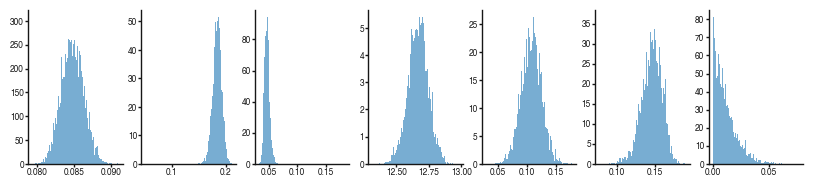

In [17]:
fig,ax = plt.subplots(1,7, figsize = (10,2))
for i in range(7):
    ax[i].hist(ns_res_aniso.samples_equal()[:,i], density = True, alpha = 0.6, bins = 100)

Do these numbers seem sensible? 

Calculate bayes factor and compare log(z) - Can we justify the more complex anisotropic model for this data?

 really we should pick alot of samples from the models when we check the fits. 

Write a function to sample 5000 points from each posterior and plot the results vs the data. Can you see any differences in fit???

## Amazing we have now shown that the simulation of benzene that we knew demonstrated that it was an anisotropic rotator, does in fact show, that benzene is an anisotropic rotator! 


But simulations is a great place to check that our model is reasonable and works in Q, $\omega$ space. Things get more complicated when we move to experimental data we have to consider how things like: 

* The resolution function 
* Multiple scattering
* Reduction of tof data to S(Q,$\omega$)
* Quantum effects
* Background scattering 
* Interactions with the sample can etc 


are affecting our data, it is much simpler to verify our analytical model on a simulation before we move to experiment! 

How can we estimate the effects or reduction / multiple scattering and quantum effects on our experimental data?? 